# TODO:
1. Представити початковi данi графiчно.

2. Розбити данi на навчальний та валiдацiйний набори.

3. Побудувати на навчальному наборi даних моделi регресiї.

4. Представити моделi графiчно (наприклад вивести частину дерева рiшень, побудувати лiнiю регресiї тощо).

5. Виконати прогнози на основi побудованих моделей.

6. Для кожної з моделей оцiнити, чи має мiсце перенавчання.

10. В задачах регресiї розрахувати для кожної моделi наступнi критерiї якостi, окремо на навчальнiй та валiдацiйнiй множинах:

• коефiцiєнт детермiнацiї R2,
• помилки RMSE, MAE та MAPE.

11. Спробувати виконати решiтчастий пошук (grid search) для пiдбору гiперпараметрiв моделей.

12. Зробити висновки про якiсть роботи моделей на дослiджених даних. На основi критерiїв якостi спробувати обрати найкращу модель.

13. Навчити моделi на пiдмножинах навчальних даних. Оцiнити, наскiльки розмiр навчальної множини впливає на якiсть моделi.

14. Кожний варiант мiстить два набори даних. Дослiдити обидва набори за наведеними вище етапами. Можна обрати власний набiр даних (повiдомивши попередньо про це викладача), наприклад, з цiкавої вам практичної задачi. Для кожного набору спробувати пiдiбрати найкращу модель.

TODO-spec:
3. Побудувати модель регресiї, використовуючи sklearn.neural_network.MLPRegressor

Початковi данi:
(а) sklearn.datasets.load_diabetes
(б) www.kaggle.com/htagholdings/property-sales

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.metrics import r2_score as R2, mean_squared_error as MSE, mean_absolute_error as MAE, mean_absolute_percentage_error as MAPE
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")
from math import ceil
from sklearn.compose import TransformedTargetRegressor

Визначимо функцію, для обчислення основних метрик оцінки регресії:

In [2]:
def metrics_calc(y_true: np.array, y_predict: np.array):
    """Функція для зручного обчислення метрик регресії"""
    metrics = {
        "r2": R2(y_true, y_predict),
        "rmse": np.sqrt(MSE(y_true, y_predict)),
        "mae": MAE(y_true, y_predict),
        "mape": MAPE(y_true, y_predict)}
    return metrics

In [4]:
# Завантажуємо набори даних
ds_1 = load_diabetes(as_frame = True).frame
ds_2 = pd.read_csv('./raw_sales.csv')

In [5]:
ds_1 # Огляд першого датасету

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


Маємо 11 ознак. Ознаки `age`, `sex`, `bmi` відповідають за вік, стать і індекс маси тіла, але мають значення у проміжку (-.2, .2), очевидно, це попередньо оброблені дані. Цільова змінна, скоріше за все, відповідає за ймовірність виявлення діабету, або значення рівня цукру для пацієнта.

Дані вже готові до роботи

In [6]:
ds_2 # Огляд другого датасету

,datesold,postcode,price,propertyType,bedrooms
0,2007-02-07 00:00:00,2607,525000,house,4
1,2007-02-27 00:00:00,2906,290000,house,3
2,2007-03-07 00:00:00,2905,328000,house,3
3,2007-03-09 00:00:00,2905,380000,house,4
4,2007-03-21 00:00:00,2906,310000,house,3
...,...,...,...,...,...
29575,2019-07-25 00:00:00,2900,500000,unit,3
29576,2019-07-25 00:00:00,2612,560000,unit,2
29577,2019-07-26 00:00:00,2912,464950,unit,2
29578,2019-07-26 00:00:00,2601,589000,unit,2


Маємо 5 ознак. `datesold` - день продажі, `postcode` - поштовий індекс, `propertyType` - приватний будинок або ж квартира, `bedrooms` - кількість кімнат. Цільова змінна вказує за яку ціну було продано нерухомість.

Поштовий індекс є не вагомим при визначенні ціни нерухомості, цю ознаку можна прибрати. Тип нерухомості приведемо до значень True/False. Дату продажі розіб'ємо на рік, місяць і день.

In [7]:
ds_2.drop(columns = ["postcode"], inplace =True) # Поштовий індекс не є вагомим, тому видаляємо його як зайву інформацію

# Переводимо дату в формат datetime і розбиваємо на місяці дні тижня
ds_2["datesold"] = pd.to_datetime(ds_2["datesold"])
ds_2['day'] = ds_2["datesold"].dt.day
ds_2["month"] = ds_2["datesold"].dt.month
ds_2['year'] = ds_2['datesold'].dt.year

# Змінюємо значення propertyType на True(unit)/False(house)
ds_2["propertyType"] = pd.get_dummies(ds_2["propertyType"], drop_first = True)

# Видаляємо початковий стовбець з часом продажу
ds_2.drop(columns = ["datesold"], inplace = True)

In [8]:
ds_2 # Тепер можна подивитись на оновлений датасет

,price,propertyType,bedrooms,day,month,year
0,525000,False,4,7,2,2007
1,290000,False,3,27,2,2007
2,328000,False,3,7,3,2007
3,380000,False,4,9,3,2007
4,310000,False,3,21,3,2007
...,...,...,...,...,...,...
29575,500000,True,3,25,7,2019
29576,560000,True,2,25,7,2019
29577,464950,True,2,26,7,2019
29578,589000,True,2,26,7,2019


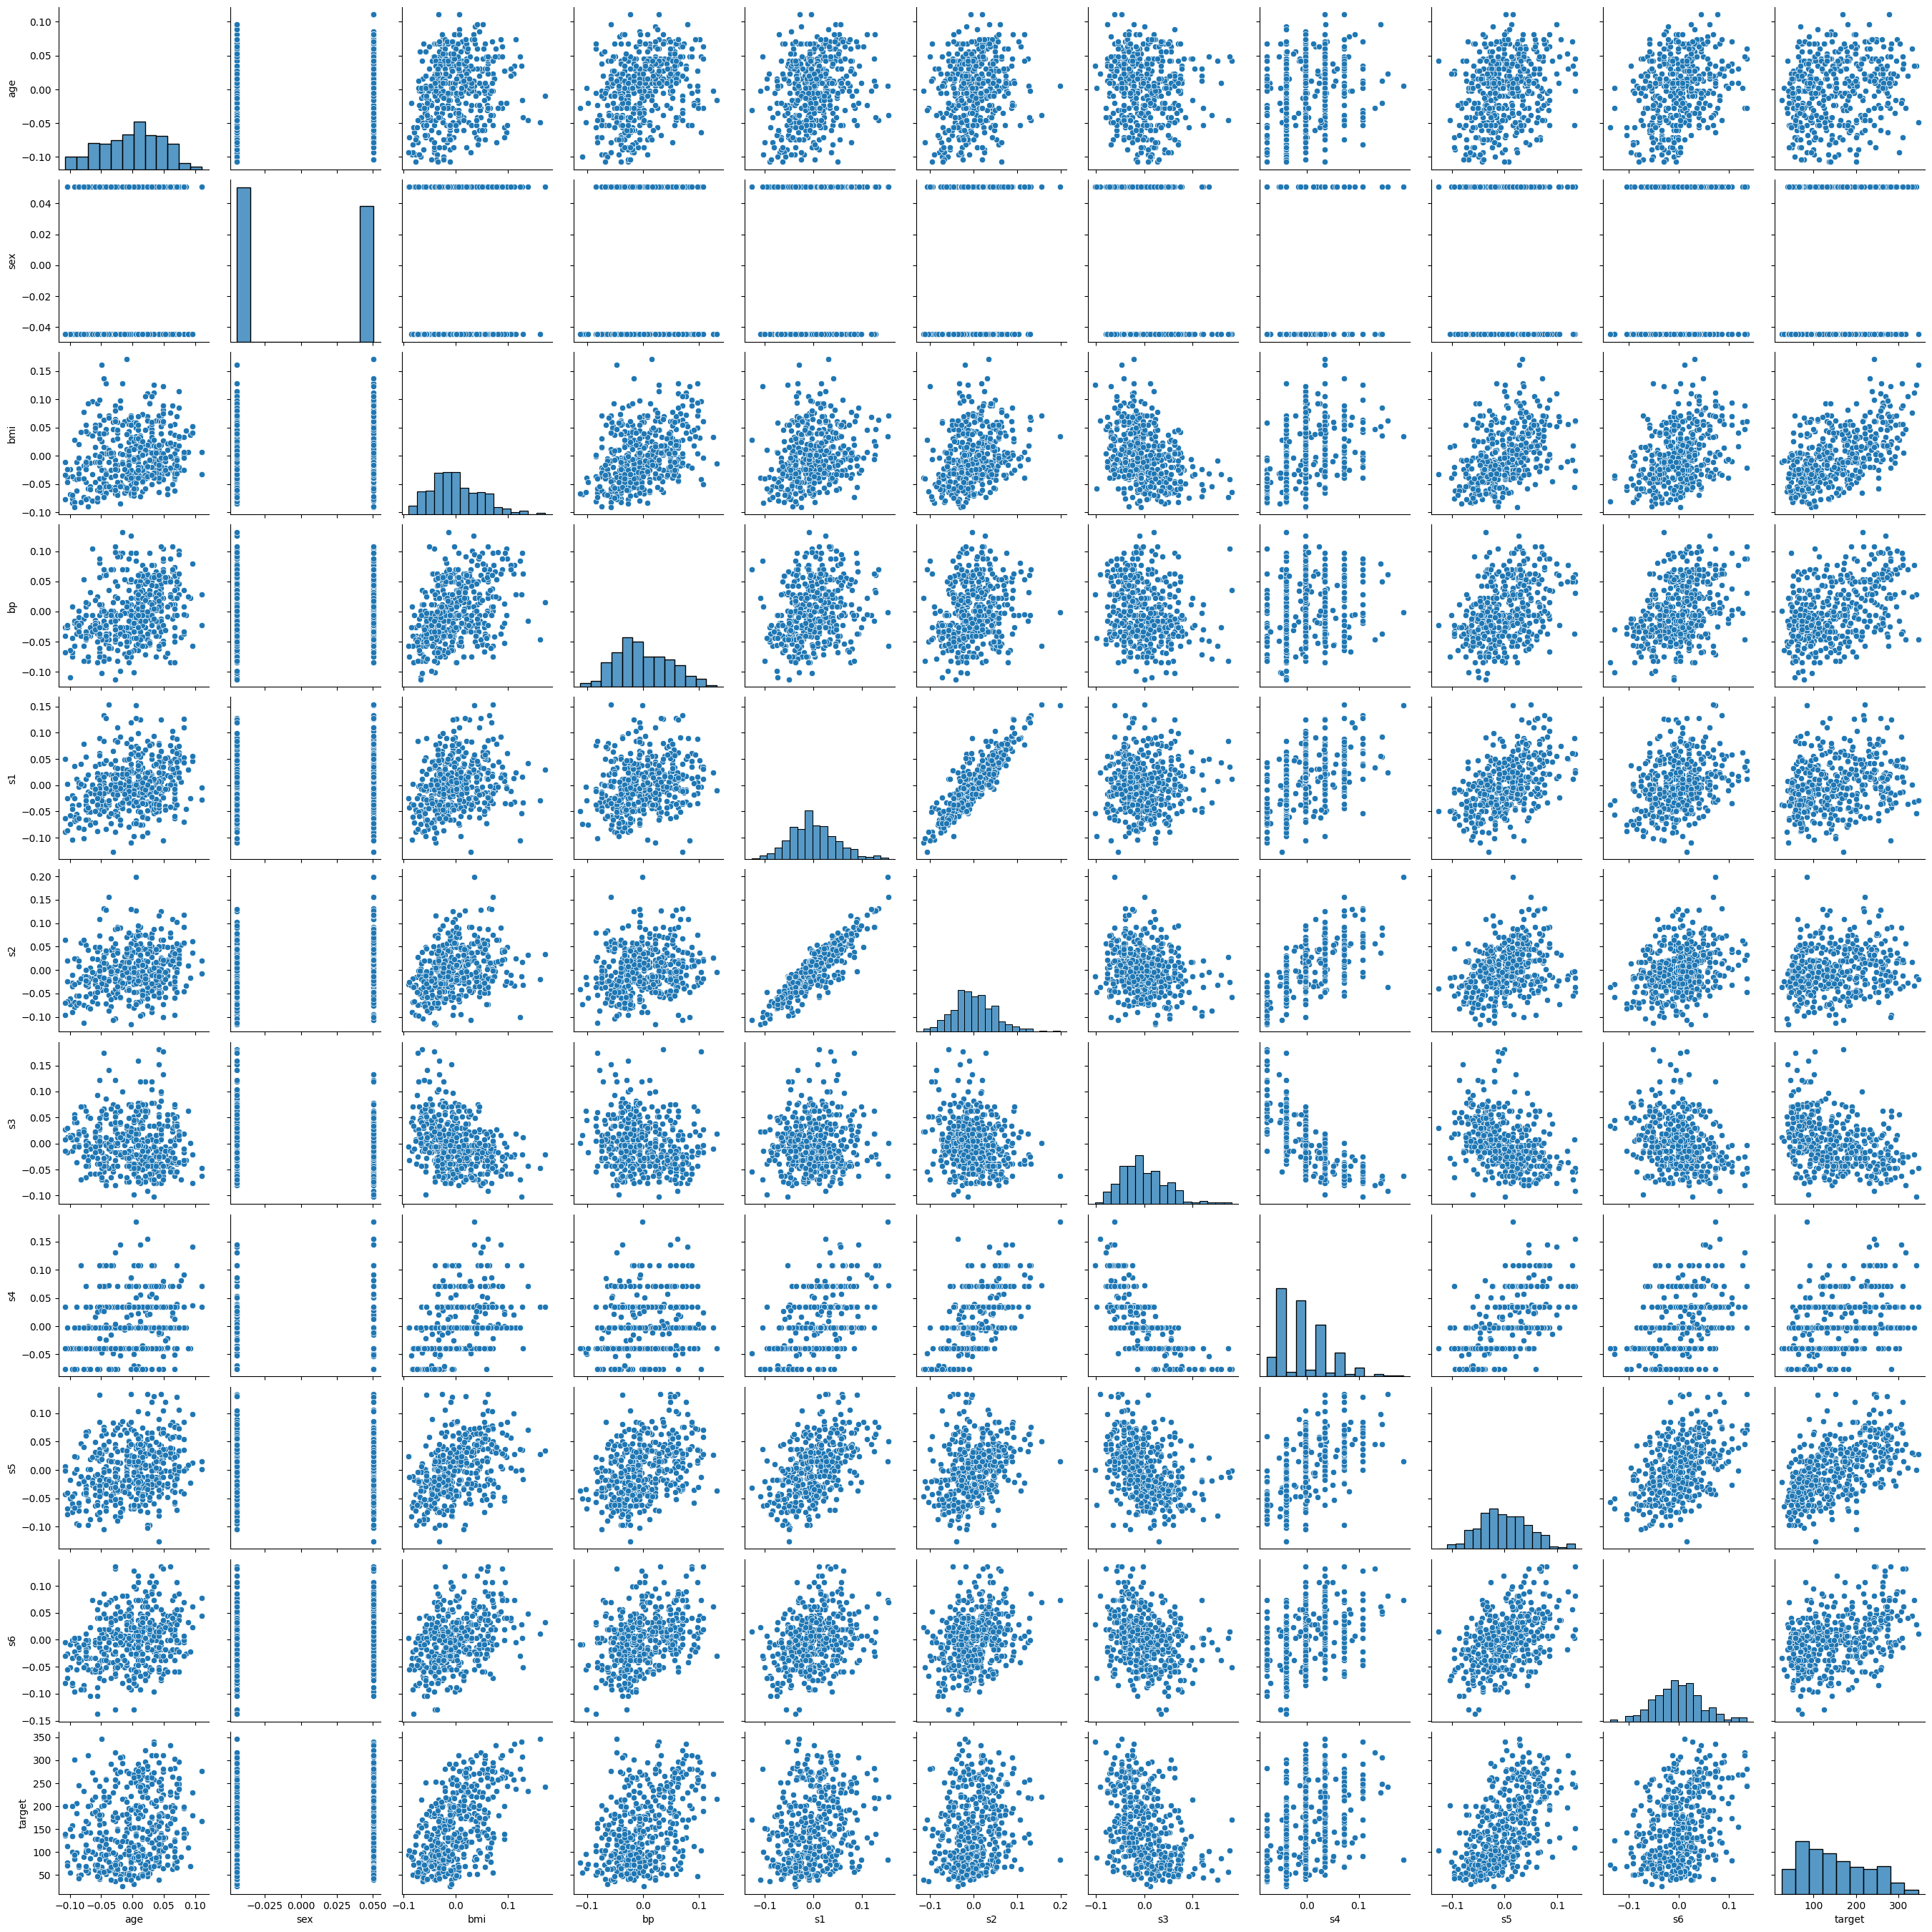

In [9]:
sns.pairplot(ds_1); # Поглянемо на розподіл ознак відносно один одної у першому датасеті

Попередньо бачимо, що найбільший вплив на значення цільової змінної мають ознаки `bmi`, `s4`, `s5`, `s6`. Менший, але значущий, вплив мають `bp`, `s2`, `s3`.


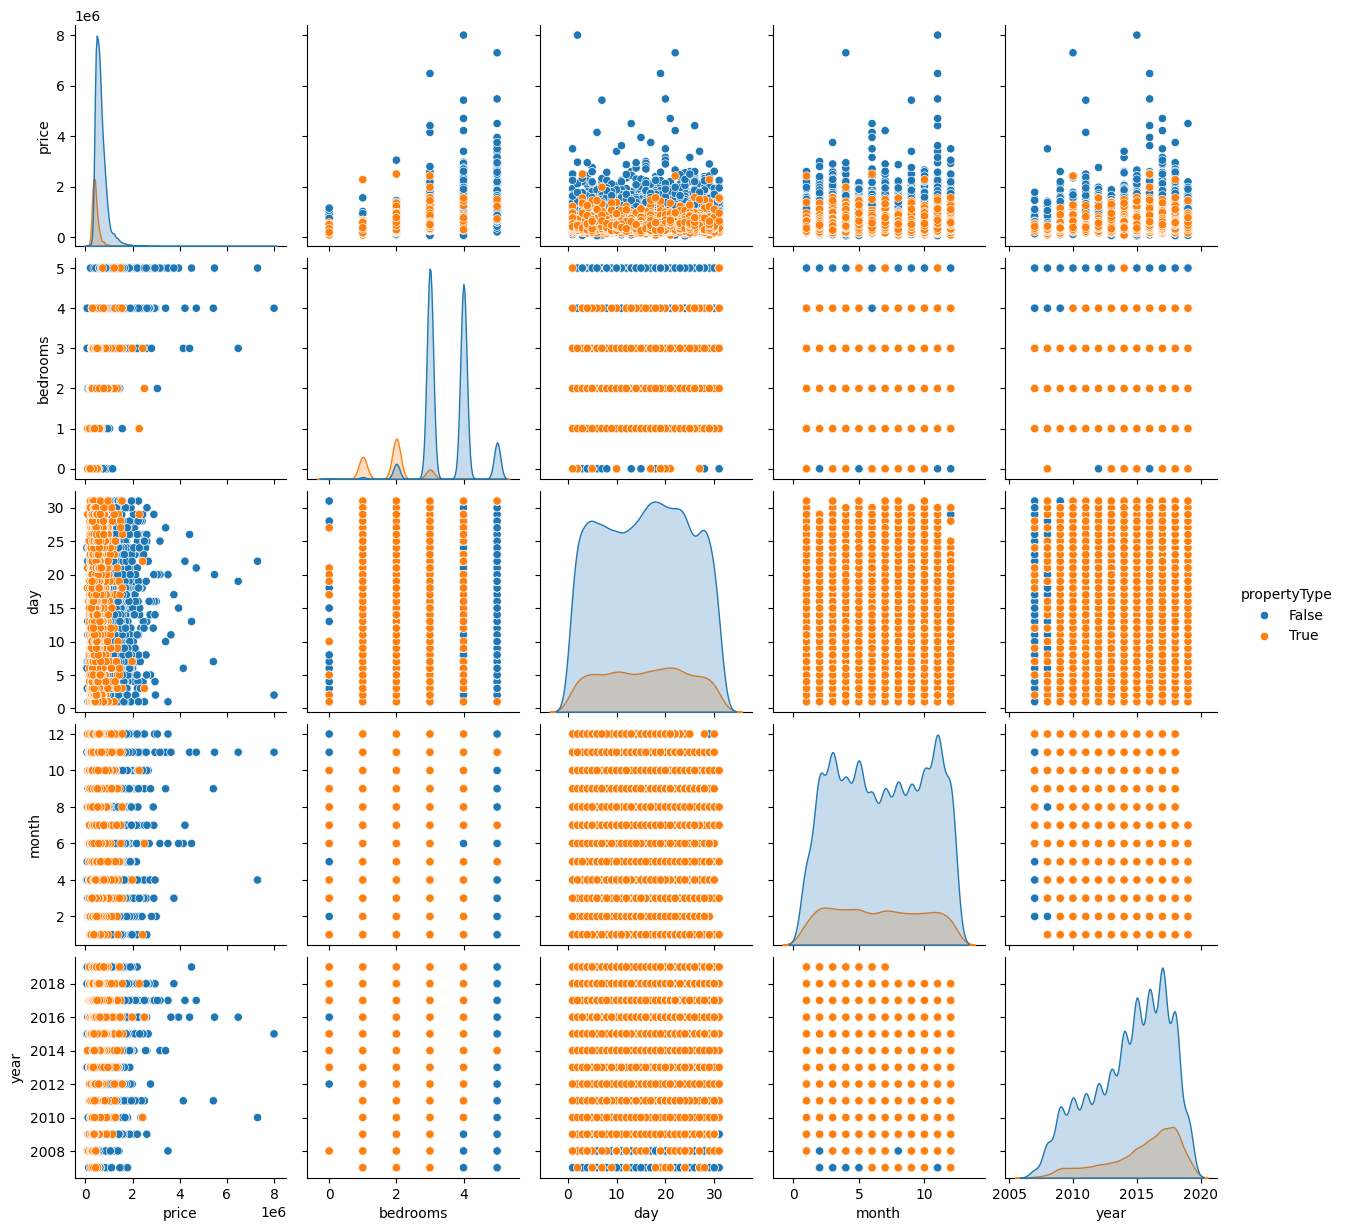

In [10]:
sns.pairplot(ds_2, hue = 'propertyType'); # Поглянемо на розподіл ознак відносно один одної у другому датасеті

Очікувано, на вартість нерухомості впливає рік продажі `year` і більшим чином кількість кімнат `bedrooms`.

Для навчання нейронних мереж ітеративно розбиватимемо набір на навчальний і тестовий в різних пропорціях - починаючи від 20% тренувального набору до 80%. Також ітеративно будемо додавати кількість нейронів до мережі й тренувати її, зберігаючи результати у DataFrame `results`.

In [61]:
# Створюємо порожній DataFrame для зберігання майбутніх результатів
results = pd.DataFrame(columns = ['architecture', 'train_size',"ds", 'r2', 'rmse', 'mae', 'mape', 'test_super_metric', 'train_super_metric'])

for train_size in np.linspace(0.5, 0.8, 3):  # Робимо цикл по розміру навчального набору

    # Розбиваємо індекси ds_1 та ds_2 у пропорції поточної ітерації циклу
    train_ds_1, test_ds_1 = train_test_split(np.arange(0, len(ds_1)), test_size=1 - train_size, random_state=42)
    train_ds_2, test_ds_2 = train_test_split(np.arange(0, len(ds_2)), test_size=1 - train_size, random_state=42)

    # За розбитими індексами розбиваємо самі набори даних. Для зручності зберігаємо їх у словнику
    dss = {
        "ds_1":{"X_train": ds_1.loc[train_ds_1].drop(columns =["target"]), "y_train": ds_1.loc[train_ds_1, ["target"]],
                "X_test": ds_1.loc[test_ds_1].drop(columns =["target"]), "y_test": ds_1.loc[test_ds_1, ["target"]], },
        "ds_2": {"X_train":ds_2.loc[train_ds_2].drop(columns =["price"]), "y_train": ds_2.loc[train_ds_2, ["price"]],
                 "X_test": ds_2.loc[test_ds_2].drop(columns =["price"]), "y_test": ds_2.loc[test_ds_2, ["price"]]}
    }

    for ds in dss: # Цикл для ітерації по обох датасетах

        for arch in [1, 5, 10, 20, 50, 100, 200, 300, 400, 500]:
            ds_X_train = dss[ds]["X_train"]
            ds_y_train = dss[ds]["y_train"]
            ds_X_test = dss[ds]["X_test"]
            ds_y_test = dss[ds]["y_test"]

            scaler = StandardScaler()
            ds_X_train = scaler.fit_transform(ds_X_train)
            ds_X_test = scaler.transform(ds_X_test)

            base_mlp = MLPRegressor(
                hidden_layer_sizes=arch,
                activation='relu',
                solver='adam',
                alpha=1e-6,                # важливо!
                learning_rate_init=0.005,  # важливо!
                max_iter=5000,
                early_stopping=True,      # для стабільності
                random_state=42,
                verbose=False
            )
            model = TransformedTargetRegressor(
            regressor = base_mlp,
            transformer = StandardScaler()
            )
            # Навчаємо модель на навчальних даних
            model.fit(ds_X_train, ds_y_train)

            # Перевіряємо модель на навчальній множині та зберігаємо результат
            y_pred = model.predict(ds_X_train)
            new_row = pd.DataFrame.from_dict(metrics_calc(ds_y_train, y_pred), orient = "index").T
            # Додаємо нову метрику, за якою оцінюватимемо якість моделі, як середнє зважене чотирьох базових метрик.
            # При r2 відʼємний коефіцієнт, тому що на відміну від mae, mape і т.д., які ми намагаємося мінімізувати, r2 ми намагаємося максимізувати. Отже, коефіцієнти при r2 та інших метриках має бути різними
            train_super_metric = (new_row['r2']  * -100 + new_row['mape'] * 100) + new_row['rmse'] + new_row['mae']

            # Перевіряємо модель на тестувальній множині та зберігаємо результат
            y_pred = model.predict(ds_X_test)
            new_row = pd.DataFrame.from_dict(metrics_calc(ds_y_test, y_pred), orient = "index").T
            new_row['train_super_metric'] = train_super_metric
            new_row['test_super_metric'] = (new_row['r2']  * -100 + new_row['mape'] * 100) + new_row['rmse'] + new_row['mae']
            new_row["ds"] = ds
            new_row['train_size'] = train_size
            new_row['architecture'] = arch
            new_row['model'] = model
            results = pd.concat([results, new_row], ignore_index=True)

In [62]:
idx = results.groupby(['ds']) # Вибираємо значення для тестових даних і групуємо
results

,architecture,train_size,ds,r2,rmse,mae,mape,test_super_metric,train_super_metric,model
0,1,0.50,ds_1,0.076399,72.506242,63.759123,0.630983,191.723724,174.364799,TransformedTargetRegressor(regressor=MLPRegres...
1,5,0.50,ds_1,0.350085,60.822127,50.594203,0.411212,117.529064,109.742458,TransformedTargetRegressor(regressor=MLPRegres...
2,10,0.50,ds_1,0.421680,57.374274,45.906849,0.402952,101.408265,69.481658,TransformedTargetRegressor(regressor=MLPRegres...
3,20,0.50,ds_1,0.440750,56.420401,45.624516,0.413151,99.284970,80.776907,TransformedTargetRegressor(regressor=MLPRegres...
4,50,0.50,ds_1,0.467768,55.040684,44.098171,0.385722,90.934245,68.588896,TransformedTargetRegressor(regressor=MLPRegres...
5,100,0.50,ds_1,0.224611,66.434417,55.076227,0.540993,153.148903,148.851430,TransformedTargetRegressor(regressor=MLPRegres...
6,200,0.50,ds_1,0.379137,59.447188,48.066375,0.427674,112.367298,110.155571,TransformedTargetRegressor(regressor=MLPRegres...
7,300,0.50,ds_1,0.425811,57.169002,46.972401,0.412574,102.817692,64.790381,TransformedTargetRegressor(regressor=MLPRegres...
8,400,0.50,ds_1,0.482271,54.285586,43.595889,0.378942,87.548586,82.059372,TransformedTargetRegressor(regressor=MLPRegres...
9,500,0.50,ds_1,0.359481,60.380844,49.637990,0.450112,119.081881,120.245814,TransformedTargetRegressor(regressor=MLPRegres...


Маємо набір результатів. Подивимось на найкращі з них.

In [63]:
best_of_the_best = idx['test_super_metric'].min(numeric_only=True)
best_of_the_best

,test_super_metric
ds,
ds_1,70.550441
ds_2,350994.249095


In [64]:
new_results = results[(results['test_super_metric'] == best_of_the_best['ds_1']) | (results['test_super_metric'] == best_of_the_best['ds_2'])]
new_results

,architecture,train_size,ds,r2,rmse,mae,mape,test_super_metric,train_super_metric,model
49,500,0.8,ds_1,0.528506,49.980486,39.507182,0.339133,70.550441,70.228147,TransformedTargetRegressor(regressor=MLPRegres...
59,500,0.8,ds_2,0.322491,213963.518118,137040.770068,0.222101,350994.249095,381605.350916,TransformedTargetRegressor(regressor=MLPRegres...


"Супер" метрика, яка є середнім зваженим більш типових метрик (r2, rmse, mae, mape), яку необхідно було мінімізувати показує, що:

  - Результати для першого набору даних поступаються результатам регресійних моделей, побудованих у минулій лабораторній на 9,4%. Крім того, бачимо, що найкраща модель для цього набору була навчена на максимально великому тренувальному наборі - 80% усього датасету, що є більш природнім показником, ніж 65% для регресійних моделей з минулої лабораторної.
  - Результати для другого набору даних поступаються звичайним регресіям лише на 0,3%

Перевіримо чи має місце перенавчання


In [65]:
new_results['Abs_difference_super_metrics'] = (new_results['test_super_metric'] - new_results['train_super_metric']) / new_results['train_super_metric']
new_results[['architecture', 'ds', 'Abs_difference_super_metrics']]

,architecture,ds,Abs_difference_super_metrics
49,500,ds_1,0.004589
59,500,ds_2,-0.080217


Бачимо, що для першого датасету модель показує себе набагато краще на навчальному наборі, ніж на тестовому. Маємо перенавчання. Це також підтверджується тим, що була обрана архітектура з 400 нейронами, очевидно, що модель з 500 нейронами ще більше перенавчена і показує ще гірші результати на тестовому наборі.
Для другого датасету маємо кращі результати на тестовому наборі ніж на тренувальному, що може свідчити про недонавчання.

In [70]:
def plot_predictions(ds: pd.DataFrame, model, target: 'str', ds_name: 'str', n_cols=3):

    X = ds.drop(columns=[target])
    y_true = ds[target]
    y_pred = model.predict(StandardScaler().fit_transform(X)).flatten()

    num_features = X.shape[1]
    n_rows = ceil(num_features / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    for i, feature in enumerate(X.columns):
        ax = axes[i]
        sns.scatterplot(x=X[feature], y=y_true, label='Actual', alpha=0.6, ax=ax)
        sns.scatterplot(x=X[feature], y=y_pred, label='Predicted', alpha=0.6, ax=ax)
        ax.set_title(f"{feature}")
        ax.set_xlabel(feature)
        ax.set_ylabel("Target")
        ax.legend()

    # Ховаємо зайві subplot-и
    for j in range(num_features, len(axes)):
        axes[j].set_visible(False)
    fig.suptitle(f'{ds_name}, {model}', fontsize=16, fontweight='bold', y=1.02)

    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.show()

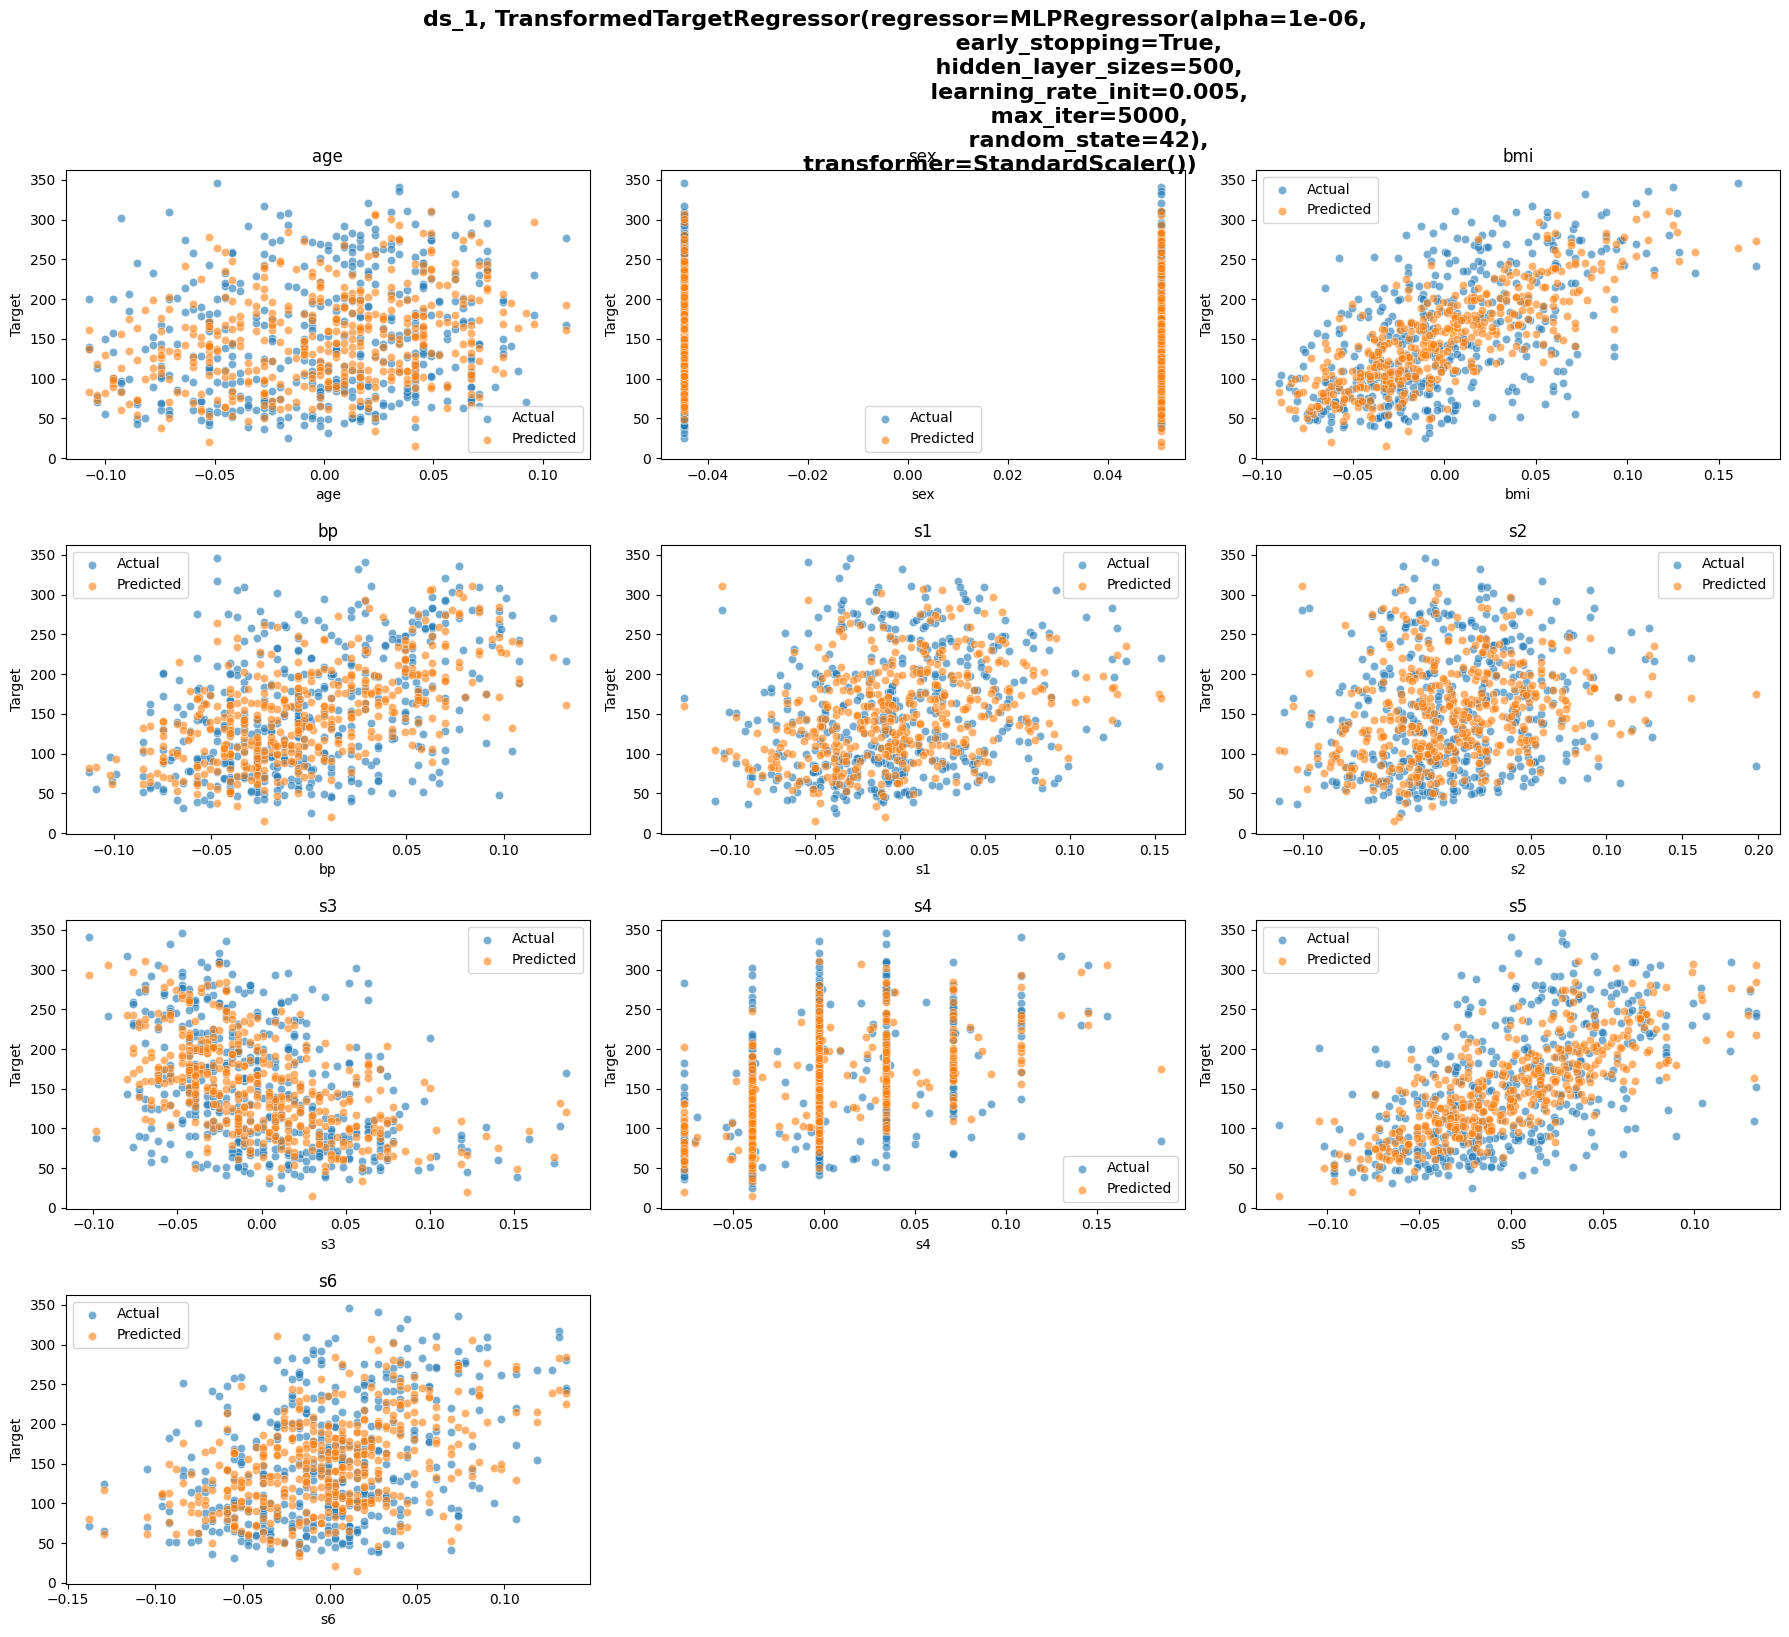

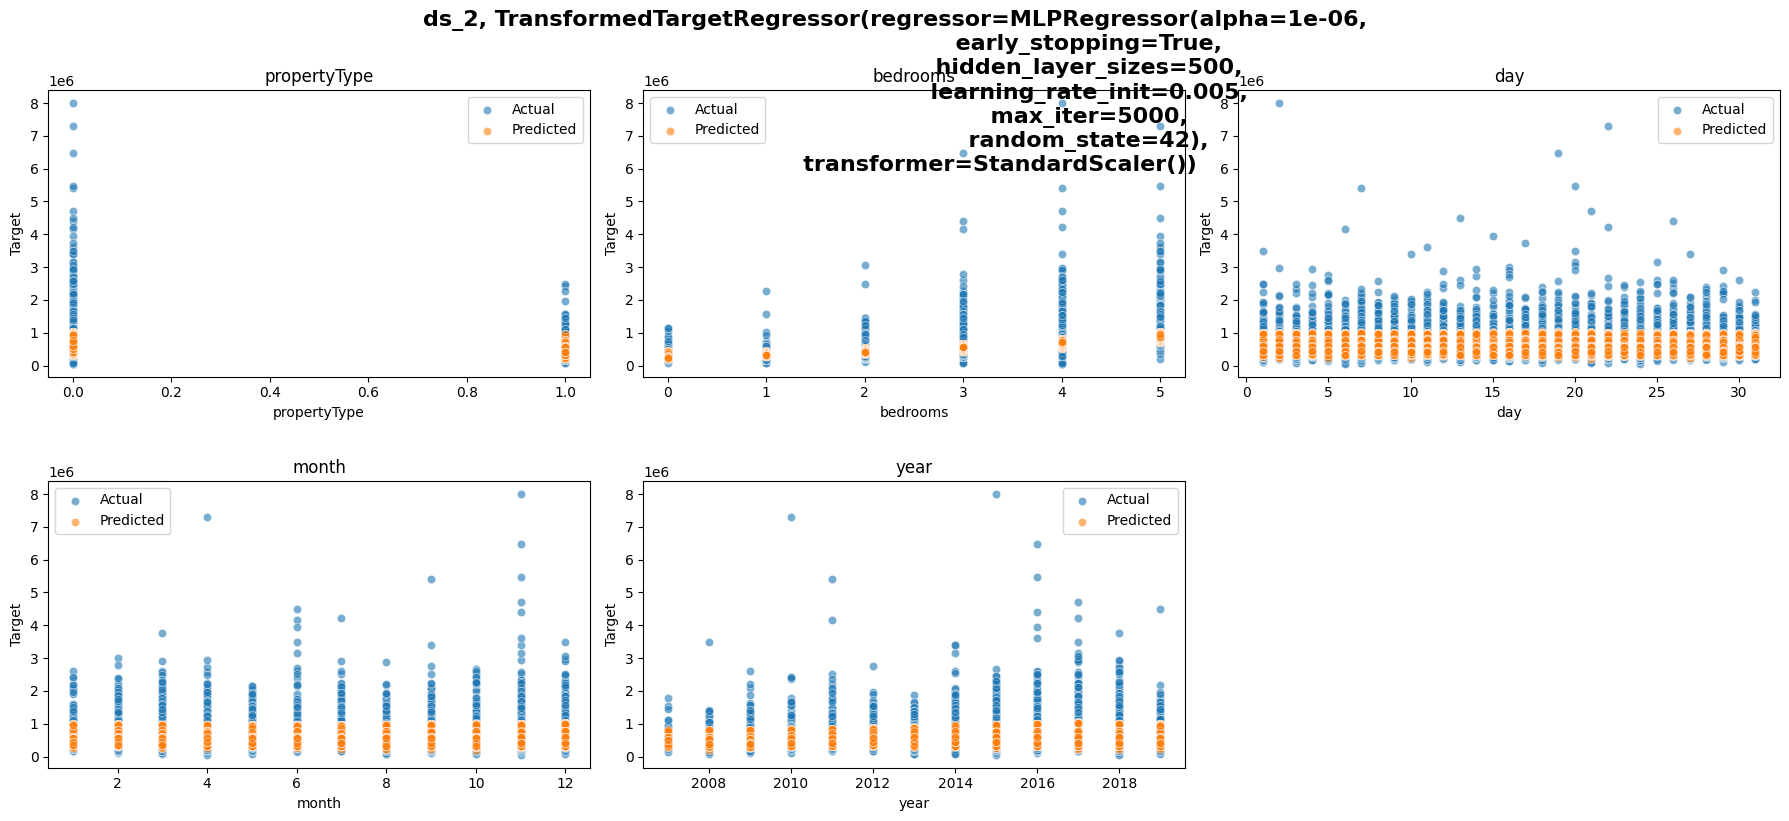

In [71]:
for model in new_results[new_results['ds'] == 'ds_1']['model']:
    plot_predictions(ds_1, model, 'target', ds_name='ds_1')

for model in new_results[new_results['ds'] == 'ds_2']['model']:
    plot_predictions(ds_2, model, 'price', ds_name='ds_2')

Тепер побудуємо дво- і тришарові мережі. Одношарові моделі показали себе найкраще на максимальному розмірі навчального набору, тому багатошарові мережі навчатимемо лише на 80% даних.

In [80]:
# Створюємо порожній DataFrame для зберігання майбутніх результатів
multilayer_results = pd.DataFrame(columns=['architecture', "ds", 'r2', 'rmse', 'mae', 'mape', 'test_super_metric', 'train_super_metric'])

# Розбиваємо індекси ds_1 та ds_2 на навчальну і тестову множину
train_ds_1, test_ds_1 = train_test_split(np.arange(0, len(ds_1)), test_size=0.2, random_state=42)
train_ds_2, test_ds_2 = train_test_split(np.arange(0, len(ds_2)), test_size=0.2, random_state=42)

# За розбитими індексами розбиваємо самі набори даних. Для зручності зберігаємо їх у словнику
dss = {
    "ds_1": {"X_train": ds_1.loc[train_ds_1].drop(columns=["target"]), "y_train": ds_1.loc[train_ds_1, ["target"]],
             "X_test": ds_1.loc[test_ds_1].drop(columns=["target"]), "y_test": ds_1.loc[test_ds_1, ["target"]], },
    "ds_2": {"X_train": ds_2.loc[train_ds_2].drop(columns=["price"]), "y_train": ds_2.loc[train_ds_2, ["price"]],
             "X_test": ds_2.loc[test_ds_2].drop(columns=["price"]), "y_test": ds_2.loc[test_ds_2, ["price"]]}
}

for ds in dss:  # Цикл для ітерації по обох датасетах

    for arch in [(100, 50), (200, 100), (300, 100), (200, 100, 50), (300, 150, 75)]:
        ds_X_train = dss[ds]["X_train"]
        ds_y_train = dss[ds]["y_train"]
        ds_X_test = dss[ds]["X_test"]
        ds_y_test = dss[ds]["y_test"]

        ds_y_train = np.ravel(ds_y_train)
        ds_y_test = np.ravel(ds_y_test)

        scaler = StandardScaler()
        ds_X_train = scaler.fit_transform(ds_X_train)
        ds_X_test = scaler.transform(ds_X_test)

        base_mlp = MLPRegressor(
            hidden_layer_sizes=arch,
            activation='relu',
            solver='adam',
            alpha=1e-6,
            learning_rate_init=0.005,
            max_iter=5000,
            early_stopping=True,
            random_state=42,
            verbose=False
        )

        model = TransformedTargetRegressor(
            regressor=base_mlp,
            transformer=StandardScaler()
        )

        # Навчаємо модель на навчальних даних
        model.fit(ds_X_train, ds_y_train)

        # Перевіряємо модель на навчальній множині та зберігаємо результат
        y_pred = model.predict(ds_X_train)
        new_row = pd.DataFrame.from_dict(metrics_calc(ds_y_train, y_pred), orient="index").T
        # Додаємо нову метрику, за якою оцінюватимемо якість моделі, як середнє зважене чотирьох базових метрик.
        # При r2 відʼємний коефіцієнт, тому що на відміну від mae, mape і т.д., які ми намагаємося мінімізувати, r2 ми намагаємося максимізувати. Отже, коефіцієнти при r2 та інших метриках має бути різними
        train_super_metric = (new_row['r2'] * -100 + new_row['mape'] * 100) + new_row['rmse'] + new_row['mae']

        # Перевіряємо модель на тестувальній множині та зберігаємо результат
        y_pred = model.predict(ds_X_test)
        new_row = pd.DataFrame.from_dict(metrics_calc(ds_y_test, y_pred), orient="index").T
        new_row['train_super_metric'] = train_super_metric
        new_row['test_super_metric'] = (new_row['r2'] * -100 + new_row['mape'] * 100) + new_row['rmse'] + new_row['mae']
        new_row["ds"] = ds
        new_row['architecture'] = [arch]
        new_row['model'] = model
        multilayer_results = pd.concat([multilayer_results, new_row], ignore_index=True)


In [81]:
idx = multilayer_results.groupby(['ds'])
best_of_the_best = idx['test_super_metric'].min(numeric_only=True)
multilayer_new_results = multilayer_results[(multilayer_results['test_super_metric'] == best_of_the_best['ds_1']) | (multilayer_results['test_super_metric'] == best_of_the_best['ds_2'])]
multilayer_new_results

,architecture,ds,r2,rmse,mae,mape,test_super_metric,train_super_metric,model
0,"(100, 50)",ds_1,0.538023,49.473494,38.502226,0.343570,68.530434,60.963341,TransformedTargetRegressor(regressor=MLPRegres...
9,"(300, 150, 75)",ds_2,0.322990,213884.726759,138466.737184,0.225461,352341.710979,381081.251089,TransformedTargetRegressor(regressor=MLPRegres...


In [82]:
multilayer_new_results['Abs_difference_super_metrics'] = (multilayer_new_results['test_super_metric'] - multilayer_new_results['train_super_metric']) / multilayer_new_results['train_super_metric']
multilayer_new_results[['architecture', 'ds', 'Abs_difference_super_metrics']]

,architecture,ds,Abs_difference_super_metrics
0,"(100, 50)",ds_1,0.124125
9,"(300, 150, 75)",ds_2,-0.075416


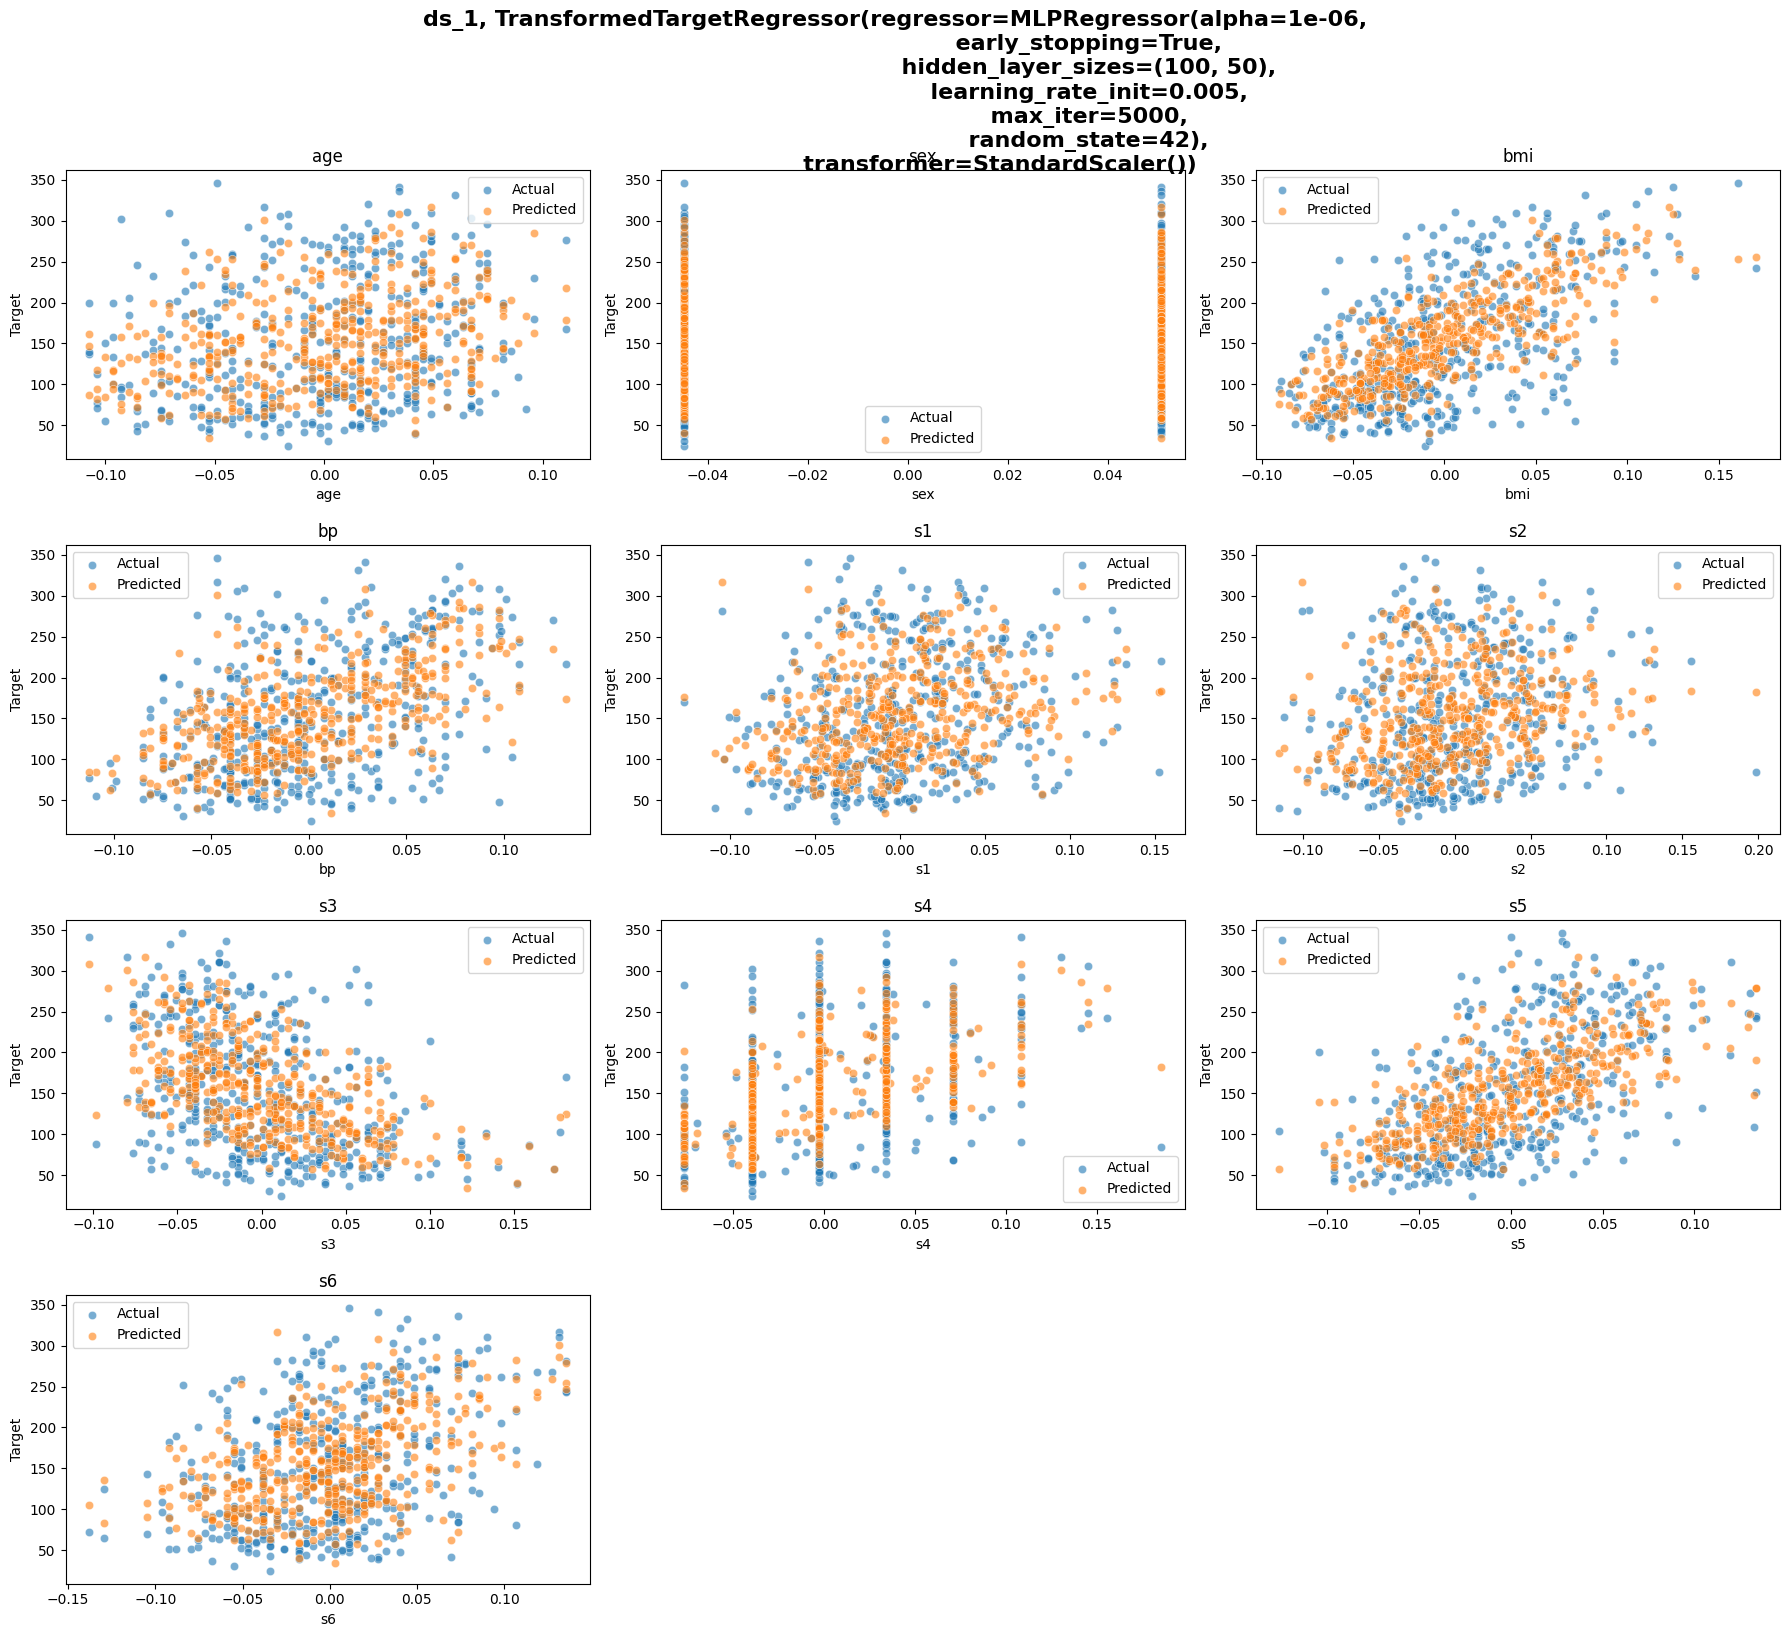

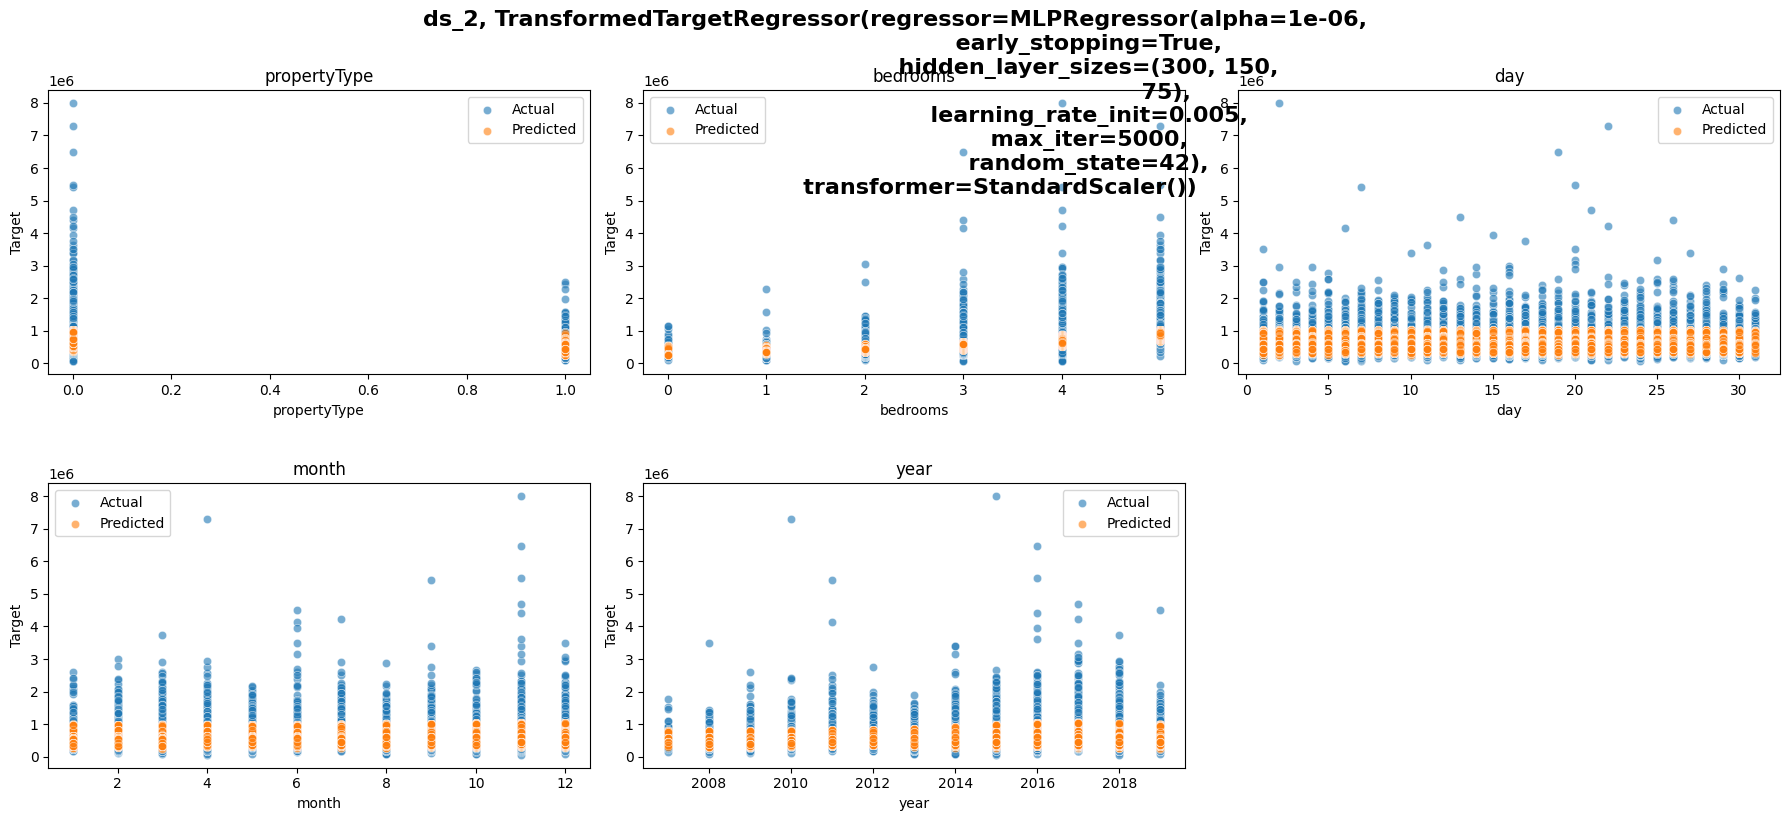

In [83]:
for model in multilayer_new_results[multilayer_new_results['ds'] == 'ds_1']['model']:
    plot_predictions(ds_1, model, 'target', ds_name='ds_1')

for model in multilayer_new_results[multilayer_new_results['ds'] == 'ds_2']['model']:
    plot_predictions(ds_2, model, 'price', ds_name='ds_2')

Висновки:
  В ході виконання роботи ми побудували декілька одношарових перцептронів з різною кількістю схованих ознак. Можемо побачити на метриках, що кількість схованих ознак дуже чутливий параметр і його збільшення покращує результати.